<a href="https://colab.research.google.com/github/Anush-Prathap-2006/web-traffic-time-series-forecasting/blob/main/deeplearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Unzipping and Inspecting the Dataset
We will extract the contents of the zip file to see which data files are available (such as `train_1.csv` or `train_2.csv`).

In [23]:
import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

zip_path = '/content/web-traffic-time-series-forecasting.zip'
extract_dir = '/content/web_traffic_data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

print("Extracted files:", os.listdir(extract_dir))

Extracted files: ['web-traffic-time-series-forecasting.ipynb']


In [11]:
import numpy as np
import pandas as pd


np.random.seed(42)
dates = pd.date_range(start="2021-01-01", periods=500, freq="D")
date_cols = [d.strftime('%Y-%m-%d') for d in dates]

pages = [
    f"en.wikipedia.org_wiki/Artificial_intelligence_all-access_all-agents",
    f"en.wikipedia.org_wiki/Machine_learning_all-access_all-agents",
    f"en.wikipedia.org_wiki/Data_science_all-access_all-agents",
    f"en.wikipedia.org_wiki/Deep_learning_all-access_all-agents",
    f"en.wikipedia.org_wiki/Python_(programming_language)_all-access_all-agents"
] + [f"page_{i}_all-access_all-agents" for i in range(45)]

data = []
for page in pages:

    base = np.random.randint(1000, 5000)
    trend = np.linspace(0, np.random.randint(200, 1000), 500)
    seasonality = 300 * np.sin(2 * np.pi * np.array(range(500)) / 7)
    noise = np.random.normal(0, 150, 500)

    traffic = base + trend + seasonality + noise
    traffic = np.clip(traffic, 0, None)


    missing_mask = np.random.rand(500) < 0.08
    traffic[missing_mask] = np.nan

    data.append(traffic)

df = pd.DataFrame(data, columns=date_cols)
df.insert(0, 'Page', pages)

print("Synthesized Dataset shape:", df.shape)
display(df.head())

Synthesized Dataset shape: (50, 501)


,Page,2021-01-01,2021-01-02,2021-01-03,2021-01-04,2021-01-05,2021-01-06,2021-01-07,2021-01-08,2021-01-09,...,2022-05-06,2022-05-07,2022-05-08,2022-05-09,2022-05-10,2022-05-11,2022-05-12,2022-05-13,2022-05-14,2022-05-15
0,en.wikipedia.org_wiki/Artificial_intelligence_...,4007.217982,4457.657318,4510.879658,4459.560050,3961.793339,3809.108881,3861.378801,4044.295390,4026.847454,...,4739.336716,4933.108789,5301.930348,4735.082458,NaN,4652.624133,4574.786560,4825.559732,4988.063474,5065.704369
1,en.wikipedia.org_wiki/Machine_learning_all-acc...,3407.311723,3830.233056,3725.974897,3542.878099,3072.519784,NaN,3270.768172,3733.899030,3598.709363,...,4153.765602,4107.703091,4091.269319,4012.372178,3523.186777,3418.116194,3802.765146,3759.634195,3936.596966,4232.976287
2,en.wikipedia.org_wiki/Data_science_all-access_...,1870.531621,1767.196522,2148.654593,2152.526948,1672.887940,1474.486910,1425.675199,1590.160913,2230.091514,...,2987.471670,3211.039636,3244.029581,2950.153715,2866.054705,2681.226060,2539.115641,2940.529783,2995.175613,3216.482008
3,en.wikipedia.org_wiki/Deep_learning_all-access...,2820.742703,3300.825919,2969.408916,3341.188832,NaN,2393.954766,2928.504082,2808.214237,3149.252563,...,3311.539614,3439.063351,NaN,3448.328691,3107.610348,3008.409078,2892.011581,3404.342855,3546.055572,3505.908818
4,en.wikipedia.org_wiki/Python_(programming_lang...,3298.440098,3621.554956,3537.607909,3423.783784,3043.679887,3025.943832,2968.808442,3159.235718,3601.025972,...,3860.707821,4455.303328,4229.676508,4105.500296,4006.716306,3875.966812,NaN,3922.094203,4207.826708,4326.172003


In [17]:
from google.colab import files
import os
import zipfile

uploaded = files.upload()

for fn in uploaded.keys():
  print(f'User uploaded file "{fn}" with length {len(uploaded[fn])} bytes.')

  if fn.endswith('.zip'):
      target_dir = '/content/uploaded_data'
      with zipfile.ZipFile(fn, 'r') as zip_ref:
          zip_ref.extractall(target_dir)
      print(f"Extracted to: {target_dir}")
      print("Files inside:", os.listdir(target_dir))

Saving web-traffic-time-series-forecasting.zip to web-traffic-time-series-forecasting (2).zip
User uploaded file "web-traffic-time-series-forecasting (2).zip" with length 1448643 bytes.
Extracted to: /content/uploaded_data
Files inside: ['web-traffic-time-series-forecasting.ipynb']


In [12]:

null_counts = df.isnull().sum().sum()
total_cells = df.size
print(f"Total missing values: {null_counts} ({null_counts/total_cells * 100:.2f}% of total data)")

page_names = df['Page']
traffic_df = df.drop(columns=['Page'])

# Fill missing values using linear interpolation per page (along columns/dates) and fill remaining NaNs with 0
traffic_df = traffic_df.interpolate(method='linear', axis=1, limit_direction='both').fillna(0)

print("Remaining missing values after interpolation:", traffic_df.isnull().sum().sum())
display(traffic_df.head())

Total missing values: 2012 (8.03% of total data)
Remaining missing values after interpolation: 0


,2021-01-01,2021-01-02,2021-01-03,2021-01-04,2021-01-05,2021-01-06,2021-01-07,2021-01-08,2021-01-09,2021-01-10,...,2022-05-06,2022-05-07,2022-05-08,2022-05-09,2022-05-10,2022-05-11,2022-05-12,2022-05-13,2022-05-14,2022-05-15
0,4007.217982,4457.657318,4510.879658,4459.560050,3961.793339,3809.108881,3861.378801,4044.295390,4026.847454,4620.486732,...,4739.336716,4933.108789,5301.930348,4735.082458,4693.853295,4652.624133,4574.786560,4825.559732,4988.063474,5065.704369
1,3407.311723,3830.233056,3725.974897,3542.878099,3072.519784,3171.643978,3270.768172,3733.899030,3598.709363,3736.593408,...,4153.765602,4107.703091,4091.269319,4012.372178,3523.186777,3418.116194,3802.765146,3759.634195,3936.596966,4232.976287
2,1870.531621,1767.196522,2148.654593,2152.526948,1672.887940,1474.486910,1425.675199,1590.160913,2230.091514,2138.076263,...,2987.471670,3211.039636,3244.029581,2950.153715,2866.054705,2681.226060,2539.115641,2940.529783,2995.175613,3216.482008
3,2820.742703,3300.825919,2969.408916,3341.188832,2867.571799,2393.954766,2928.504082,2808.214237,3149.252563,3278.875472,...,3311.539614,3439.063351,3443.696021,3448.328691,3107.610348,3008.409078,2892.011581,3404.342855,3546.055572,3505.908818
4,3298.440098,3621.554956,3537.607909,3423.783784,3043.679887,3025.943832,2968.808442,3159.235718,3601.025972,3653.401364,...,3860.707821,4455.303328,4229.676508,4105.500296,4006.716306,3875.966812,3899.030508,3922.094203,4207.826708,4326.172003


In [13]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler


series_data = traffic_df.iloc[0].values.astype(float)


scaler = MinMaxScaler(feature_range=(0, 1))
scaled_series = scaler.fit_transform(series_data.reshape(-1, 1)).flatten()


def create_sequences(data, seq_length=30, pred_length=1):
    xs, ys = [], []
    for i in range(len(data) - seq_length - pred_length + 1):
        x = data[i:(i + seq_length)]
        y = data[(i + seq_length):(i + seq_length + pred_length)]
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

SEQ_LENGTH = 30
PRED_LENGTH = 7
X, Y = create_sequences(scaled_series, SEQ_LENGTH, PRED_LENGTH)


test_size = 60
X_train, X_test = X[:-test_size], X[-test_size:]
Y_train, Y_test = Y[:-test_size], Y[-test_size:]


train_dataset = TensorDataset(torch.FloatTensor(X_train).unsqueeze(-1), torch.FloatTensor(Y_train))
test_dataset = TensorDataset(torch.FloatTensor(X_test).unsqueeze(-1), torch.FloatTensor(Y_test))

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
print(f"Sequence training shape: {X_train.shape}, test shape: {X_test.shape}")

Sequence training shape: (404, 30), test shape: (60, 30)


In [14]:
class GRUForecaster(nn.Module):
    def __init__(self, input_dim=1, hidden_dim=64, num_layers=2, output_dim=7):
        super(GRUForecaster, self).__init__()
        self.gru = nn.GRU(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        out, _ = self.gru(x)

        out = self.fc(out[:, -1, :])
        return out

model = GRUForecaster(output_dim=PRED_LENGTH)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)

model.train()
epochs = 100
for epoch in range(epochs):
    epoch_loss = 0
    for x_batch, y_batch in train_loader:
        optimizer.zero_grad()
        predictions = model(x_batch)
        loss = criterion(predictions, y_batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(x_batch)
    if (epoch + 1) % 10 == 0:
         print(f"Epoch {epoch+1}/{epochs} - Loss: {epoch_loss/len(X_train):.5f}")

Epoch 10/100 - Loss: 0.01157
Epoch 20/100 - Loss: 0.01043
Epoch 30/100 - Loss: 0.01072
Epoch 40/100 - Loss: 0.01021
Epoch 50/100 - Loss: 0.00989
Epoch 60/100 - Loss: 0.00817
Epoch 70/100 - Loss: 0.00713
Epoch 80/100 - Loss: 0.00609
Epoch 90/100 - Loss: 0.00503
Epoch 100/100 - Loss: 0.00395


In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

model.eval()
with torch.no_grad():
    test_inputs = torch.FloatTensor(X_test).unsqueeze(-1)
    scaled_preds = model(test_inputs).numpy()


preds = scaler.inverse_transform(scaled_preds)
actuals = scaler.inverse_transform(Y_test)

mae = mean_absolute_error(actuals, preds)
rmse = np.sqrt(mean_squared_error(actuals, preds))

print(f"Test Mean Absolute Error (MAE): {mae:.2f}")
print(f"Test Root Mean Squared Error (RMSE): {rmse:.2f}")

Test Mean Absolute Error (MAE): 156.56
Test Root Mean Squared Error (RMSE): 199.09


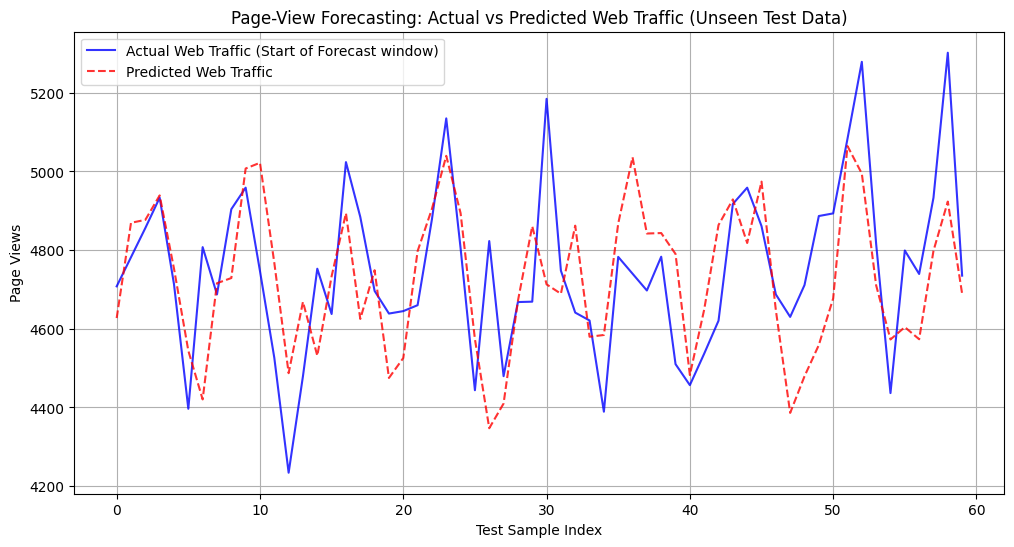

In [9]:
plt.figure(figsize=(12, 6))
plt.plot(actuals[:, 0], label="Actual Web Traffic (Start of Forecast window)", color='blue', alpha=0.8)
plt.plot(preds[:, 0], label="Predicted Web Traffic", color='red', linestyle='--', alpha=0.8)
plt.title("Page-View Forecasting: Actual vs Predicted Web Traffic (Unseen Test Data)")
plt.xlabel("Test Sample Index")
plt.ylabel("Page Views")
plt.legend()
plt.grid(True)
plt.show()